# Laboratorio 2 – Clasificador de Acciones de Tutela por asunto
**Categorías:** Derecho al trabajo · Mínimo vital · Meritocracia

Ejecute las celdas en orden (Entorno de ejecución → Ejecutar todas).
1. Sube los documentos de la carpeta de OneDrive (como .zip).
2. Extrae el texto, lo anonimiza y lo parte en fragmentos.
3. Propone una categoría para cada documento, que **ustedes deben revisar**.
4. Guarda `dataset.csv` con el formato del laboratorio.
5. Entrena el clasificador y muestra dónde se equivoca.

## 0. Instalación y configuración

In [1]:
!pip -q install pdfplumber python-docx pytesseract pdf2image
!apt-get -qq install -y tesseract-ocr tesseract-ocr-spa poppler-utils > /dev/null

import os, re, zipfile, unicodedata
import pandas as pd

CARPETA = '/content/tutelas'          # aquí quedan los documentos
REVISADO_POR = 'Escriba su nombre'    # quién aprueba las etiquetas
MAX_FRAGMENTOS_POR_DOC = 5            # fragmentos que se toman de cada tutela
PALABRAS_POR_FRAGMENTO = 180          # tamaño aproximado (1-2 párrafos)

CATEGORIAS = {
    'Derecho al trabajo': [
        'derecho al trabajo', 'estabilidad laboral', 'reintegro', 'despido', 'despedid',
        'terminacion del contrato', 'terminacion unilateral', 'desvincul', 'fuero',
        'contrato de trabajo', 'empleador', 'debilidad manifiesta', 'insubsistencia'],
    'Mínimo vital': [
        'minimo vital', 'subsistencia', 'sustento', 'salarios adeudados', 'pago de salarios',
        'incapacidad', 'mesada', 'pension', 'no cuenta con otros ingresos', 'unico ingreso',
        'congrua', 'cuota alimentaria', 'embargo'],
    'Meritocracia': [
        'merito', 'concurso', 'lista de elegibles', 'cnsc', 'comision nacional del servicio civil',
        'carrera administrativa', 'convocatoria', 'periodo de prueba', 'nombramiento',
        'opec', 'cargos publicos', 'elegible'],
}

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 57.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 63.1 MB/s eta 0:00:00
E: Failed to fetch http://security.ubuntu.com/ubuntu/pool/main/p/poppler/poppler-utils_24.02.0-1ubuntu9.9_amd64.deb  404  Not Found [IP: 185.125.190.81 80]
E: Unable to fetch some archives, maybe run apt-get update or try with --fix-missing?


## 1. Subir los documentos
En OneDrive pulse **Descargar** sobre la carpeta: se baja un `.zip`. Súbalo aquí (también puede subir PDF, DOCX o TXT sueltos).

Si dentro del zip hay subcarpetas con el nombre del tema (p. ej. `trabajo`, `minimo vital`, `meritocracia`), se usan como etiqueta.

In [2]:
from google.colab import files
os.makedirs(CARPETA, exist_ok=True)
subidos = files.upload()
for nombre in subidos:
    if nombre.lower().endswith('.zip'):
        with zipfile.ZipFile(nombre) as z:
            z.extractall(CARPETA)
    else:
        os.replace(nombre, os.path.join(CARPETA, nombre))
print('Listo. Archivos en', CARPETA)

Saving 1. DEMANDA T-2026-00377-00W.pdf to 1. DEMANDA T-2026-00377-00W.pdf
Saving 1. DEMANDA_4e8bb109303147b1b78d430eeb4e4c06 (1).PDF to 1. DEMANDA_4e8bb109303147b1b78d430eeb4e4c06 (1).PDF
Saving 1. DEMANDA_5_9_2026, 4_35_03 p. m_.pdf to 1. DEMANDA_5_9_2026, 4_35_03 p. m_.pdf
Saving 1. DEMANDA_9_9_2026, 5_30_49 p. m_.pdf to 1. DEMANDA_9_9_2026, 5_30_49 p. m_.pdf
Saving 1. EscritoTutela (1).pdf to 1. EscritoTutela (1).pdf
Saving 1. EscritoTutela 20260908.pdf to 1. EscritoTutela 20260908.pdf
Saving 1. EscritoTutela.pdf to 1. EscritoTutela.pdf
Saving 1.1. Auto (28).pdf to 1.1. Auto (28).pdf
Saving 1.1. Auto (34).pdf to 1.1. Auto (34).pdf
Saving 1.1. Auto (35).pdf to 1.1. Auto (35).pdf
Saving 1.1. Autoadmitetut_AUTOADMITETUTELAYDEC_0_20260914110650751 (1).PDF to 1.1. Autoadmitetut_AUTOADMITETUTELAYDEC_0_20260914110650751 (1).PDF
Saving 1.1. Autoqueadmite_202607282AdmiteConvo_0_20260911093608823.PDF to 1.1. Autoqueadmite_202607282AdmiteConvo_0_20260911093608823.PDF
Saving 1.2. Anexos (15).pd

## 2. Extraer el texto de cada documento

In [3]:
def leer_documento(ruta):
    ext = ruta.lower().rsplit('.', 1)[-1]
    try:
        if ext == 'pdf':
            import pdfplumber
            with pdfplumber.open(ruta) as pdf:
                t = '\n'.join((p.extract_text() or '') for p in pdf.pages)
            if len(t.split()) < 50:      # PDF escaneado: leerlo con OCR
                import pytesseract
                from pdf2image import convert_from_path
                print('   OCR (puede tardar):', os.path.basename(ruta))
                t = '\n\n'.join(pytesseract.image_to_string(img, lang='spa')
                                  for img in convert_from_path(ruta, dpi=200))
            return t
        if ext == 'docx':
            import docx
            return '\n'.join(p.text for p in docx.Document(ruta).paragraphs)
        if ext == 'txt':
            return open(ruta, encoding='utf-8', errors='ignore').read()
    except Exception as e:
        print('No se pudo leer', ruta, '->', e)
    return ''

# zips dentro de la carpeta (OneDrive a veces los anida)
for raiz, _, archivos in list(os.walk(CARPETA)):
    for a in archivos:
        if a.lower().endswith('.zip'):
            with zipfile.ZipFile(os.path.join(raiz, a)) as z:
                z.extractall(os.path.join(raiz, a[:-4]))

todos = [os.path.join(r, a) for r, _, fs in os.walk(CARPETA) for a in fs]
ignorados = [t for t in todos if t.lower().rsplit('.', 1)[-1] not in ('pdf', 'docx', 'txt', 'zip')]
print(len(todos), 'archivos encontrados en', CARPETA)
if ignorados:
    print('Formatos que NO se leen (conviértalos a PDF o DOCX):', [os.path.basename(i) for i in ignorados])
assert todos, 'No hay archivos. Vuelva a ejecutar la celda 1 y suba el .zip o los documentos.'

docs = []
for raiz, _, archivos in os.walk(CARPETA):
    for a in sorted(archivos):
        if a.lower().rsplit('.', 1)[-1] in ('pdf', 'docx', 'txt'):
            ruta = os.path.join(raiz, a)
            docs.append({'archivo': a,
                         'subcarpeta': os.path.relpath(raiz, CARPETA),
                         'texto_bruto': leer_documento(ruta)})
docs = pd.DataFrame(docs, columns=['archivo', 'subcarpeta', 'texto_bruto'])
docs['palabras'] = docs['texto_bruto'].str.split().str.len()

vacios = docs[docs['palabras'] < 50]
if len(vacios):
    print('OJO: de estos archivos no se pudo sacar texto ni con OCR:')
    print(vacios['archivo'].to_string(index=False))
docs = docs[docs['palabras'] >= 50].reset_index(drop=True)
print(len(docs), 'documentos con texto')
assert len(docs), 'Ningún documento tiene texto legible. Revise los avisos de arriba.'
docs[['archivo', 'subcarpeta', 'palabras']]

21 archivos encontrados en /content/tutelas
21 documentos con texto


,archivo,subcarpeta,palabras
0,1. DEMANDA T-2026-00377-00W.pdf,.,186480
1,1. DEMANDA_4e8bb109303147b1b78d430eeb4e4c06 (1...,.,2775
2,"1. DEMANDA_5_9_2026, 4_35_03 p. m_.pdf",.,3194
3,"1. DEMANDA_9_9_2026, 5_30_49 p. m_.pdf",.,1814
4,1. EscritoTutela (1).pdf,.,174052
5,1. EscritoTutela 20260908.pdf,.,3242
6,1. EscritoTutela.pdf,.,174052
7,1.1. Auto (28).pdf,.,504
8,1.1. Auto (34).pdf,.,751
9,1.1. Auto (35).pdf,.,218


## 3. Limpieza y anonimización
Se eliminan cédulas, teléfonos, correos, radicados y direcciones, y se reemplazan por marcas genéricas.
**Los nombres propios no se pueden borrar de forma confiable con reglas automáticas: revísenlos a mano en el CSV antes de entregar.**

In [4]:
def sin_tildes(t):
    return ''.join(c for c in unicodedata.normalize('NFD', t) if unicodedata.category(c) != 'Mn')

def anonimizar(t):
    t = re.sub(r'\S+@\S+', '[CORREO]', t)
    t = re.sub(r'\b\d{5}[-\s]?\d{2}[-\s]?\d{2}[-\s]?\d{3}[-\s]?\d{4}[-\s]?\d{5}[-\s]?\d{2}\b', '[RADICADO]', t)
    t = re.sub(r'(?i)(radicad[oa]|rad\.|expediente)\s*(n[o°º.]*)?\s*:?\s*[\d\-\s]{6,}', r'\1 [RADICADO] ', t)
    t = re.sub(r'(?i)(c\.?\s?c\.?|c[eé]dula( de ciudadan[ií]a)?|nit|t\.?\s?p\.?)\s*(n[o°º.]*)?\s*:?\s*[\d\.\,\-]{5,}', r'\1 [ID]', t)
    t = re.sub(r'(?i)\b(calle|carrera|cra|cl|kr|avenida|av|diagonal|transversal)\.?\s*\d+\s*[a-z]?\s*(sur|norte|bis)?\s*(#|n[o°º.]*)\s*\d+\s*[a-z]?\s*-\s*\d+', '[DIRECCION]', t)
    t = re.sub(r'\b(3\d{2}[\s\-]?\d{3}[\s\-]?\d{4}|60\d[\s\-]?\d{7})\b', '[TELEFONO]', t)
    t = re.sub(r'\b\d{1,3}(\.\d{3}){2,3}\b', '[ID]', t)
    return t

def limpiar(t):
    t = anonimizar(t)
    t = re.sub(r'-\n', '', t)             # palabras cortadas al final de línea
    t = re.sub(r'[ \t]+', ' ', t)
    t = re.sub(r'\n\s*\n+', '\n\n', t)   # conserva separación de párrafos
    return t.strip()

docs['texto_limpio'] = docs['texto_bruto'].apply(limpiar)
print(docs['texto_limpio'].iloc[0][:800])

Honorables Magistrados
CORTE SUPREMA DE JUSTICIA
CONSEJO DE ESTADO
(REPARTO)
ASUNTO : ACCIÓN DE TUTELA.
ACCIONANTE : JAMES E CIFUENTES MALDONADO
ACCIONADA : NACIÓN — RAMA JUDICIAL
CONSEJO SUPERIOR DE LA JUDICATURA UNIDAD
DE ADMIN. DE LA CARRERA JUDICIAL
VINCULADAS : DIRECCIÓN EJECUTIVA DE ADMIN JUDICIAL
UNIVERSIDAD LIBRE (Contrato Nº 249 de 2025).
JAMES EDINSON CIFUENTES MALDONADO, mayor de edad, identificado
con la cédula de ciudadanía [ID] abogado en ejercicio con tarjeta
profesional N.º 122348 del Consejo Superior de la Judicatura, domiciliado en
Pereira (Risaralda), actuando en nombre propio, promuevo acción de tutela
contra la Unidad de Administración de la Carrera Judicial del Consejo Superior de la
Judicatura, con fundamento en el artículo 86 de la Constitución Política y en el
Decr


## 4. Proponer la categoría de cada tutela
Si el archivo venía en una subcarpeta con el nombre del tema, se usa esa. Si no, se cuenta cuántas expresiones clave de cada categoría aparecen y se propone la que más pesa.
Esto es solo una **sugerencia**: la columna `puntajes` les muestra qué tan reñida estuvo la decisión.

In [5]:
def puntajes(t):
    t = sin_tildes(t.lower())
    return {cat: sum(t.count(p) for p in pals) for cat, pals in CATEGORIAS.items()}

def categoria_por_carpeta(sub):
    s = sin_tildes(sub.lower())
    halladas = []
    if 'merit' in s or 'concurso' in s: halladas.append('Meritocracia')
    if 'minimo' in s or 'vital' in s: halladas.append('Mínimo vital')
    if 'trabajo' in s or 'laboral' in s: halladas.append('Derecho al trabajo')
    # solo sirve si el nombre apunta a UNA categoría (una carpeta llamada
    # "Trabajo, mínimo vital y meritocracia" no dice nada de cada documento)
    return halladas[0] if len(halladas) == 1 else None

def sugerir(fila):
    c = categoria_por_carpeta(fila['subcarpeta'] + ' ' + fila['archivo'])
    if c: return c
    p = fila['puntajes']
    return max(p, key=p.get) if max(p.values()) > 0 else 'SIN CLASIFICAR'

docs['puntajes'] = docs['texto_limpio'].apply(puntajes)
docs['categoria'] = [sugerir(f) for _, f in docs.iterrows()]
print(docs['categoria'].value_counts())
docs[['archivo', 'categoria', 'puntajes']]

categoria
Meritocracia      20
SIN CLASIFICAR     1
Name: count, dtype: int64


,archivo,categoria,puntajes
0,1. DEMANDA T-2026-00377-00W.pdf,Meritocracia,"{'Derecho al trabajo': 5, 'Mínimo vital': 4, '..."
1,1. DEMANDA_4e8bb109303147b1b78d430eeb4e4c06 (1...,Meritocracia,"{'Derecho al trabajo': 1, 'Mínimo vital': 2, '..."
2,"1. DEMANDA_5_9_2026, 4_35_03 p. m_.pdf",Meritocracia,"{'Derecho al trabajo': 6, 'Mínimo vital': 0, '..."
3,"1. DEMANDA_9_9_2026, 5_30_49 p. m_.pdf",Meritocracia,"{'Derecho al trabajo': 0, 'Mínimo vital': 1, '..."
4,1. EscritoTutela (1).pdf,Meritocracia,"{'Derecho al trabajo': 1, 'Mínimo vital': 2, '..."
5,1. EscritoTutela 20260908.pdf,Meritocracia,"{'Derecho al trabajo': 2, 'Mínimo vital': 0, '..."
6,1. EscritoTutela.pdf,Meritocracia,"{'Derecho al trabajo': 1, 'Mínimo vital': 2, '..."
7,1.1. Auto (28).pdf,Meritocracia,"{'Derecho al trabajo': 0, 'Mínimo vital': 0, '..."
8,1.1. Auto (34).pdf,Meritocracia,"{'Derecho al trabajo': 0, 'Mínimo vital': 0, '..."
9,1.1. Auto (35).pdf,SIN CLASIFICAR,"{'Derecho al trabajo': 0, 'Mínimo vital': 0, '..."


### Corregir etiquetas a mano (opcional pero recomendado)
Escriba aquí el nombre del archivo y la categoría correcta para los que la sugerencia haya fallado.

In [6]:
CORRECCIONES = {
    # 'nombre_del_archivo.pdf': 'Mínimo vital',
}
for archivo, cat in CORRECCIONES.items():
    assert cat in CATEGORIAS, f'Categoría no válida: {cat}'
    docs.loc[docs['archivo'] == archivo, 'categoria'] = cat
sin = docs[docs['categoria'] == 'SIN CLASIFICAR']
if len(sin):
    print('Sin categoría (asígnela en CORRECCIONES o se excluyen):', list(sin['archivo']))
docs = docs[docs['categoria'] != 'SIN CLASIFICAR'].reset_index(drop=True)
assert len(docs), 'Ningún documento quedó con categoría. Asígnelas en CORRECCIONES.'
print(docs['categoria'].value_counts())

Sin categoría (asígnela en CORRECCIONES o se excluyen): ['1.1. Auto (35).pdf']
categoria
Meritocracia    20
Name: count, dtype: int64


## 5. Construir el dataset (fragmentos de 1–2 párrafos)
Una misma tutela suele invocar varios derechos, así que **cada fragmento se etiqueta por lo que dice ese fragmento**; si no es claro, hereda la categoría del documento.
De cada tutela se toman los fragmentos que más hablan de hechos, derechos y pretensiones (no los encabezados ni las notificaciones).

In [7]:
PISTAS = ['pretens', 'solicit', 'hechos', 'derecho', 'vulnera', 'amparo', 'tutelar', 'ordenar', 'accionad']

def fragmentar(texto):
    palabras, frags, actual = 0, [], []
    for parrafo in texto.split('\n\n'):
        n = len(parrafo.split())
        if n == 0: continue
        actual.append(parrafo.replace('\n', ' ')); palabras += n
        if palabras >= PALABRAS_POR_FRAGMENTO:
            frags.append(' '.join(actual)); actual, palabras = [], 0
    if palabras >= 60: frags.append(' '.join(actual))
    # párrafos muy largos (PDF sin saltos): cortar por número de palabras
    salida = []
    for f in frags:
        w = f.split()
        for i in range(0, len(w), PALABRAS_POR_FRAGMENTO * 2):
            trozo = w[i:i + PALABRAS_POR_FRAGMENTO * 2]
            if len(trozo) >= 60: salida.append(' '.join(trozo))
    if not salida and len(texto.split()) >= 20:   # documento corto: va entero
        salida = [' '.join(texto.split())]
    return salida

def mejores_fragmentos(texto):
    frags = fragmentar(texto)
    orden = sorted(range(len(frags)),
                   key=lambda i: -sum(sin_tildes(frags[i].lower()).count(p) for p in PISTAS))
    return [frags[i] for i in sorted(orden[:MAX_FRAGMENTOS_POR_DOC])]

filas = []
for _, d in docs.iterrows():
    for f in mejores_fragmentos(d['texto_limpio']):
        p = puntajes(f)                       # cada fragmento se etiqueta por su propio contenido
        orden_p = sorted(p.values(), reverse=True)
        cat = max(p, key=p.get) if orden_p[0] > orden_p[1] else d['categoria']
        if d['archivo'] in CORRECCIONES or categoria_por_carpeta(d['subcarpeta'] + ' ' + d['archivo']):
            cat = d['categoria']              # etiqueta dada por ustedes o por la carpeta: se respeta
        filas.append({'texto': f, 'categoria': cat, 'origen': 'real_anonimizado',
                      'revisado_por': REVISADO_POR, 'documento': d['archivo']})
dataset = pd.DataFrame(filas, columns=['texto', 'categoria', 'origen', 'revisado_por', 'documento'])
assert len(dataset), 'No se generaron fragmentos: ejecute de nuevo las celdas 2 a 4 y revise sus avisos.'
dataset.insert(0, 'id', range(1, len(dataset) + 1))

print('Fragmentos por categoría (mínimo del laboratorio: 15 por categoría):')
print(dataset['categoria'].value_counts())
dataset.to_csv('dataset.csv', index=False, encoding='utf-8-sig')
dataset.head()

Fragmentos por categoría (mínimo del laboratorio: 15 por categoría):
categoria
Meritocracia          80
Derecho al trabajo     4
Name: count, dtype: int64


,id,texto,categoria,origen,revisado_por,documento
0,1,con el Municipio de Pereira desde hace más de ...,Meritocracia,real_anonimizado,Escriba su nombre,1. DEMANDA T-2026-00377-00W.pdf
1,2,"nadie haya evaluado mi conocimiento, por un an...",Meritocracia,real_anonimizado,Escriba su nombre,1. DEMANDA T-2026-00377-00W.pdf
2,3,de éxito y expidió la constancia de inscripció...,Meritocracia,real_anonimizado,Escriba su nombre,1. DEMANDA T-2026-00377-00W.pdf
3,4,del Acuerdo PCSJA25-12348 de 2025. TERCERA: OR...,Derecho al trabajo,real_anonimizado,Escriba su nombre,1. DEMANDA T-2026-00377-00W.pdf
4,5,2025” Únicamente serán objeto de revisión las ...,Meritocracia,real_anonimizado,Escriba su nombre,1. DEMANDA T-2026-00377-00W.pdf


In [8]:
# Descargar el dataset (entregable 2). Ábralo, revise etiquetas y nombres propios.
from google.colab import files
files.download('dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Si corrigió el CSV a mano, quite el `#` de la celda siguiente para subirlo y entrenar con la versión revisada.

In [9]:
# from google.colab import files
# files.upload()   # suba dataset.csv corregido
# dataset = pd.read_csv('dataset.csv')

## 6. Entrenar el clasificador
El texto se convierte en números (TF-IDF: qué palabras pesan en cada fragmento) y se entrena una regresión logística.
Los fragmentos de una misma tutela van todos a entrenamiento o todos a prueba, para que el modelo no "reconozca" el documento.

categoria
Meritocracia          80
Derecho al trabajo     4
Name: count, dtype: int64 

Entrenamiento: 57 fragmentos | Prueba: 27 fragmentos

                    precision    recall  f1-score   support

Derecho al trabajo       1.00      1.00      1.00         2
      Meritocracia       1.00      1.00      1.00        25

          accuracy                           1.00        27
         macro avg       1.00      1.00      1.00        27
      weighted avg       1.00      1.00      1.00        27



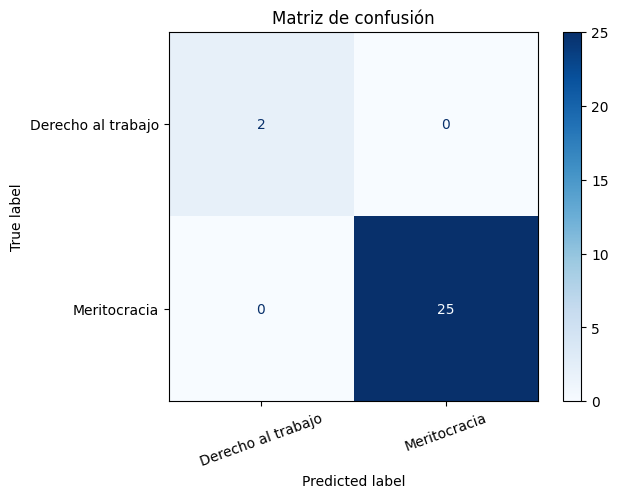

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

STOP = ['de','la','que','el','en','y','a','los','del','se','las','por','un','para','con','no','una','su',
        'al','lo','como','mas','pero','sus','le','ya','o','este','si','porque','esta','entre','cuando',
        'muy','sin','sobre','tambien','me','hasta','hay','donde','quien','desde','todo','nos','durante',
        'e','esto','mi','ante','ser','es','fue','ha','han','son','id','radicado','correo','telefono','direccion']

if 'documento' not in dataset: dataset['documento'] = dataset['id']
X, y, grupos = dataset['texto'], dataset['categoria'], dataset['documento']

from sklearn.model_selection import train_test_split
print(y.value_counts(), '\n')
assert y.nunique() >= 2, ('Todos los fragmentos quedaron en una sola categoría (' + str(y.iloc[0]) +
    '). Corrija etiquetas en CORRECCIONES o en dataset.csv: se necesitan al menos 2 categorías.')
pocas = y.value_counts()[y.value_counts() < 4]
if len(pocas):
    print('Se excluyen categorías con menos de 4 fragmentos:', list(pocas.index))
    dataset = dataset[~dataset['categoria'].isin(pocas.index)].reset_index(drop=True)
    X, y, grupos = dataset['texto'], dataset['categoria'], dataset['documento']
    assert y.nunique() >= 2, 'Solo una categoría tiene suficientes fragmentos. Agregue más documentos de las otras.'

# Se busca una división por documento en la que todas las categorías queden en ambos lados
tr = te = None
if grupos.nunique() >= 6:
    for semilla in range(200):
        a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=semilla).split(X, y, grupos))
        if y.iloc[a].nunique() == y.nunique() and y.iloc[b].nunique() == y.nunique():
            tr, te = a, b; break
if tr is None:   # no fue posible por documento: división por fragmento
    print('Aviso: la división se hizo por fragmento (hay pocos documentos por categoría); '
          'la exactitud puede salir optimista.')
    tr, te = train_test_split(list(range(len(X))), test_size=0.3, random_state=42, stratify=y)

modelo = make_pipeline(
    TfidfVectorizer(lowercase=True, strip_accents='unicode', stop_words=STOP, ngram_range=(1, 2), min_df=1),
    LogisticRegression(max_iter=1000, class_weight='balanced'))
modelo.fit(X.iloc[tr], y.iloc[tr])
pred = modelo.predict(X.iloc[te])

print('Entrenamiento:', len(tr), 'fragmentos | Prueba:', len(te), 'fragmentos\n')
print(classification_report(y.iloc[te], pred, zero_division=0))
etiquetas = sorted(y.unique())
ConfusionMatrixDisplay(confusion_matrix(y.iloc[te], pred, labels=etiquetas), display_labels=etiquetas).plot(cmap='Blues', xticks_rotation=20)
plt.title('Matriz de confusión'); plt.show()

## 7. ¿Dónde se equivoca? (para responder las preguntas del punto 6)

In [11]:
prueba = dataset.iloc[te].copy()
prueba['prediccion'] = pred
errores = prueba[prueba['categoria'] != prueba['prediccion']]
print(len(errores), 'errores de', len(prueba))
pd.set_option('display.max_colwidth', 400)
errores[['id', 'documento', 'categoria', 'prediccion', 'texto']]

0 errores de 27


,id,documento,categoria,prediccion,texto


In [12]:
# Palabras que más pesan en cada categoría: ayuda a ver si el modelo aprendió criterios jurídicos o "trucos"
import numpy as np
vec, clf = modelo.steps[0][1], modelo.steps[1][1]
terminos = np.array(vec.get_feature_names_out())
for i, cat in enumerate(clf.classes_):
    coef = clf.coef_[i] if clf.coef_.shape[0] > 1 else (clf.coef_[0] if i == 1 else -clf.coef_[0])
    print(f'{cat}:', ', '.join(terminos[np.argsort(coef)[-12:][::-1]]))

Derecho al trabajo: constancia oficial, contradiccion, oficial, exitosa, fueron, cuantos, todos, constancia, falta, documento, ambos, detecto
Meritocracia: derecho, convocatoria, 28, convocatoria 28, fecha, merito, concurso, constitucional, bogota, superior, medida, consejo


## 8. Probar con un texto nuevo

In [13]:
texto_nuevo = '''Solicito se tutele mi derecho de acceso a cargos públicos, pues ocupé el primer lugar
en la lista de elegibles del concurso de méritos y la entidad no ha efectuado el nombramiento en período de prueba.'''

probs = modelo.predict_proba([limpiar(texto_nuevo)])[0]
for cat, p in sorted(zip(modelo.classes_, probs), key=lambda x: -x[1]):
    print(f'{cat:22s} {p:.0%}')

Meritocracia           80%
Derecho al trabajo     20%
